# RCEL 506: Classification & Logistic Regression
### Case study: will a McDonald's Egypt delivery arrive within the 30-minute promise?

**Part A: Lecture.** What classification is, why linear regression fails for yes/no questions, how logistic regression works, and how to judge a classifier.

**Part B: Project.** Clean the LogiNext auto-allocation dataset, explore it visually, build a logistic regression model, evaluate it honestly, and turn it into a business recommendation.

> Run the cells top to bottom. Part A uses the same data as Part B, so the setup cells run first.

## 0. Setup

In [1]:
# In Google Colab, mount Drive first:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

# One consistent, colorblind-safe look
BLUE, ORANGE, GREEN, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
sns.set_theme(style="whitegrid", palette=[BLUE, ORANGE, GREEN, YELLOW])
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "axes.spines.top": False,
                     "axes.spines.right": False})
pct = mtick.PercentFormatter(1.0)

In [3]:
# Dataset: LogiNext auto-allocation export (one day of orders, 20 Sep 2022).
# The raw file contains rider names, phone numbers and customer addresses, so it is not published in this repo.
file_path = 'data.xlsx'  # Colab: '/content/drive/MyDrive/Colab Notebooks/Project 506_Auto_allocation.xlsx'
df_raw = pd.read_excel(file_path)
print(df_raw.shape)
print(list(df_raw.columns))

(19815, 26)
['AWB No', 'Order No.', 'Client Name', 'Order Branch', 'Origin', 'Destination', 'Order Type', 'Order State', 'Order Date', 'Start Date', 'End Date', 'Payment Type', 'Order Value', 'Payment Subtype', 'Order Status', 'Rider', 'Rider Mobile Number', 'DB Employee ID', 'Assigned Through', 'Trip No.', 'Planned Checkout Time', 'Start Time (Actual)', 'End Time (Actual)', 'Total Distance(Km)', 'Start Time (Estimated)', 'End Time (Estimated)']


---
# PART A: LECTURE

## A1. What is classification?
Machine-learning problems split by **what we predict**:

| | **Regression** | **Classification** |
|---|---|---|
| Output | A number | A category (label) |
| Example question | *How many minutes will this delivery take?* | *Will this delivery be on time: yes or no?* |
| Example algorithms | Linear regression, Random Forest regressor | **Logistic regression**, decision tree, Random Forest classifier |
| How we judge it | R², MAE | Accuracy, precision, recall, F1, ROC-AUC |

**Binary classification** has two classes (on-time / late, fraud / not fraud, churn / stay).
**Multi-class** has more (Cairo / Giza / Alexandria).

**Logistics examples:** Will the order be late? Will the customer cancel? Will the rider accept the job? Is this address likely to fail delivery?

**Why switch to classification for our project?** Last time we predicted the exact delivery *minutes* (regression) and got R² ≈ 0.19. Delivery minutes are noisy (traffic, a customer who doesn't pick up the phone). But the business doesn't really need the exact minute. It needs to know: **will we break the 30-minute promise?** That is a yes/no question, so it's a classification problem.

## A2. Why not just use linear regression for a yes/no target?
Code the target as 1 = on time, 0 = late, and fit a straight line. Problems:
1. The line predicts values **below 0 and above 1**, which can't be probabilities.
2. A straight line forces the same effect everywhere. In reality, once you have plenty of time buffer, extra buffer barely changes anything.

Let's see it on our own data. **Slack** = 30 min − allocation delay − planned ride time, i.e. how much spare time the order has when the rider leaves.

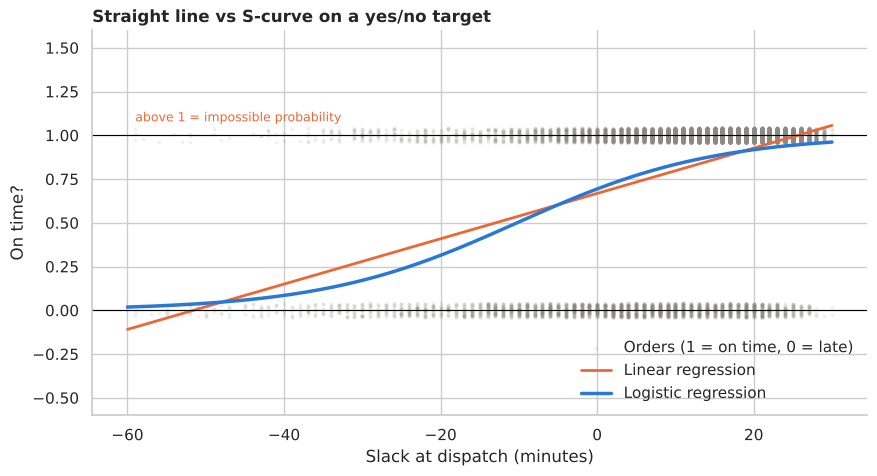

Linear regression predicts 1.06 at slack=30 and -0.11 at slack=-60  -> impossible 'probabilities'.
Logistic regression stays between 0 and 1: 0.96 and 0.02.


In [4]:
# Quick prep just for this demo (full cleaning happens in Part B)
F = '%d/%m/%Y %I:%M %p'
demo = df_raw[df_raw['Order Status'] == 'Delivered'].copy()
for c in ['Order Date', 'Start Time (Actual)', 'End Time (Actual)',
          'Start Time (Estimated)', 'End Time (Estimated)']:
    demo[c] = pd.to_datetime(demo[c], format=F, errors='coerce')
mins = lambda a, b: (demo[a] - demo[b]).dt.total_seconds() / 60
demo['slack'] = 30 - mins('Start Time (Actual)', 'Order Date') - mins('End Time (Estimated)', 'Start Time (Estimated)')
demo['on_time'] = (mins('End Time (Actual)', 'Order Date') <= 30).astype(int)
demo = demo.dropna(subset=['slack']).query('-60 <= slack <= 30')

x = demo[['slack']].values; y = demo['on_time'].values
lin = LinearRegression().fit(x, y)
logit = LogisticRegression().fit(x, y)
grid = np.linspace(-60, 30, 200).reshape(-1, 1)

fig, ax = plt.subplots()
jitter = np.random.default_rng(0).uniform(-0.04, 0.04, len(y))
ax.scatter(x, y + jitter, s=4, alpha=0.08, color=GREY, label='Orders (1 = on time, 0 = late)')
ax.plot(grid, lin.predict(grid), color=ORANGE, lw=2, label='Linear regression')
ax.plot(grid, logit.predict_proba(grid)[:, 1], color=BLUE, lw=2.5, label='Logistic regression')
ax.axhline(0, color='black', lw=0.8); ax.axhline(1, color='black', lw=0.8)
ax.text(-59, 1.08, 'above 1 = impossible probability', color=ORANGE, fontsize=9)
ax.set_ylim(-0.6, 1.6); ax.set_xlabel('Slack at dispatch (minutes)'); ax.set_ylabel('On time?')
ax.set_title('Straight line vs S-curve on a yes/no target')
ax.legend(loc='lower right', frameon=False)
plt.show()
print(f"Linear regression predicts {lin.predict([[30]])[0]:.2f} at slack=30 and {lin.predict([[-60]])[0]:.2f} at slack=-60  -> impossible 'probabilities'.")
print(f"Logistic regression stays between 0 and 1: {logit.predict_proba([[30]])[0,1]:.2f} and {logit.predict_proba([[-60]])[0,1]:.2f}.")

## A3. How logistic regression works
**Step 1: a linear score** (exactly like linear regression):
$$z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots$$

**Step 2: squash the score into a probability** with the **sigmoid** function:
$$p = \frac{1}{1 + e^{-z}}$$
Any z (−∞ to +∞) becomes a probability between 0 and 1. z = 0 gives p = 0.5.

**Step 3: decide.** If p ≥ threshold (default 0.5), predict class 1, otherwise class 0. The threshold is a *business* choice (see Part B).

**Reading the coefficients: odds.**
* Odds = p / (1 − p). A probability of 0.8 means odds of 4 to 1.
* The model is linear in **log-odds**: $\log(\text{odds}) = z$.
* So **$e^{\beta}$ = odds ratio**: each 1-unit increase in x multiplies the odds by $e^{\beta}$.
  * $e^{\beta}$ = 1.5 → odds go up 50%. $e^{\beta}$ = 0.7 → odds drop 30%.

**How it learns:** it picks the β values that make the observed outcomes most likely (*maximum likelihood*, which minimises **log-loss**), instead of minimising squared error.

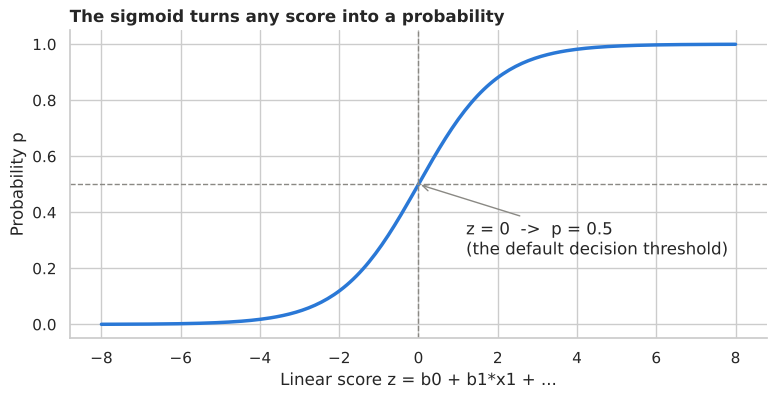

In [5]:
z = np.linspace(-8, 8, 200)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(z, 1 / (1 + np.exp(-z)), color=BLUE, lw=2.5)
ax.axhline(0.5, ls='--', color=GREY, lw=1); ax.axvline(0, ls='--', color=GREY, lw=1)
ax.annotate('z = 0  ->  p = 0.5\n(the default decision threshold)', (0, 0.5), xytext=(1.2, 0.25),
            arrowprops=dict(arrowstyle='->', color=GREY))
ax.set_xlabel('Linear score z = b0 + b1*x1 + ...'); ax.set_ylabel('Probability p')
ax.set_title('The sigmoid turns any score into a probability')
plt.show()

## A4. How do we judge a classifier?
Everything starts from the **confusion matrix** (here "positive" = on time):

| | Predicted late | Predicted on time |
|---|---|---|
| **Actually late** | True Negative (TN) | False Positive (FP): we promised, it was late |
| **Actually on time** | False Negative (FN) | True Positive (TP) |

| Metric | Formula | Plain English |
|---|---|---|
| Accuracy | (TP+TN) / all | % of all predictions that were right |
| Precision | TP / (TP+FP) | When we say "on time", how often is it? |
| Recall | TP / (TP+FN) | Of the truly on-time orders, how many did we catch? |
| F1 | harmonic mean of precision & recall | Balance of the two |
| **ROC-AUC** | area under the ROC curve | Chance the model ranks a random on-time order above a random late one. **0.5 = coin flip, 1.0 = perfect** |

**Two traps to teach:**
1. **Class imbalance.** If 83% of orders are on time, a "model" that always says *on time* scores 83% accuracy and is useless. Always compare against this **baseline**, and prefer AUC / balanced accuracy / recall on the minority class.
2. **Data leakage.** Using information that is only known *after* the outcome (e.g. actual delivery time) gives scores near 1.0 that collapse in real use. A score that looks too good to be true usually is.

---
# PART B: PROJECT
**Business question:** at the moment an order is dispatched, can we predict whether it will reach the customer **within the 30-minute promise**? If we can flag the risky ones, a supervisor can intervene (re-assign, prioritise, call the customer).

## B1. Data cleaning
Issues found in the raw file and how we fix them:

| Issue | Fix |
|---|---|
| Dates stored as text (`20/09/2022 11:58 PM`) parsed with guesswork, causing warnings | Parse with an explicit format `%d/%m/%Y %I:%M %p` |
| Columns with one value for every row (`Client Name`, `Order Type`, `Order State`) | Drop: no information |
| Rider / mobile / employee ID are 99.5% empty (and personal data) | Drop |
| `Origin` duplicates `Order Branch`; `Planned Checkout Time` ≈ `End Time (Estimated)` | Drop duplicates |
| Cancelled / not-dispatched orders have no delivery outcome | Keep **Delivered** orders only |
| Missing timestamps | Drop those rows |
| Impossible values (negative or 0-minute rides, 20-hour allocations, ETAs over 2 hours) | Keep 0–120 min ranges |

In [6]:
df = df_raw.copy()
log = [('Raw file', len(df))]

# 1. Parse dates with an explicit format (fast + no guessing)
F = '%d/%m/%Y %I:%M %p'
time_cols = ['Order Date', 'Start Time (Actual)', 'End Time (Actual)',
             'Start Time (Estimated)', 'End Time (Estimated)']
for c in time_cols:
    df[c] = pd.to_datetime(df[c], format=F, errors='coerce')

# 2. Drop uninformative / duplicate / personal columns
constant = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
drop_cols = constant + ['Rider', 'Rider Mobile Number', 'DB Employee ID', 'Origin',
                        'Planned Checkout Time', 'Start Date', 'End Date', 'Payment Subtype']
df = df.drop(columns=drop_cols)
print('Dropped columns:', drop_cols)

# 3. Delivered orders only (cancelled orders have no on-time outcome)
df = df[df['Order Status'] == 'Delivered']
log.append(('Delivered orders only', len(df)))

# 4. Rows with all needed timestamps
df = df.dropna(subset=time_cols)
log.append(('All timestamps present', len(df)))

# 5. Durations in minutes
mins = lambda a, b: (df[a] - df[b]).dt.total_seconds() / 60
df['alloc_delay']   = mins('Start Time (Actual)', 'Order Date')               # order -> rider leaves
df['planned_ride']  = mins('End Time (Estimated)', 'Start Time (Estimated)')  # system's ETA for the ride
df['actual_ride']   = mins('End Time (Actual)', 'Start Time (Actual)')        # what really happened
df['total_minutes'] = mins('End Time (Actual)', 'Order Date')                 # what the customer felt

# 6. Plausible ranges only
df = df[df['alloc_delay'].between(0, 120) & df['planned_ride'].between(1, 120) &
        df['actual_ride'].between(1, 120)]
log.append(('Plausible time ranges', len(df)))

display(pd.DataFrame(log, columns=['Step', 'Rows']).assign(
        Removed=lambda t: (-t['Rows'].diff()).fillna(0).astype(int)))

Dropped columns: ['Client Name', 'Order Type', 'Order State', 'Rider', 'Rider Mobile Number', 'DB Employee ID', 'Origin', 'Planned Checkout Time', 'Start Date', 'End Date', 'Payment Subtype']


,Step,Rows,Removed
0,Raw file,19815,0
1,Delivered orders only,19007,808
2,All timestamps present,18818,189
3,Plausible time ranges,18395,423


## B2. Target and derived features
**Target `on_time`**: 1 if the customer received the order within **30 minutes** of placing it (the promised delivery window: `End Date − Start Date` is exactly 30 minutes for every order), else 0.

**Features**: only information available **at the moment of dispatch**:

| Feature | Meaning | Why it might matter |
|---|---|---|
| `alloc_delay` | Minutes from order to rider leaving | Time already burned before the ride |
| `planned_ride` | System's ETA for the ride | Long rides leave less margin |
| `slack` | 30 − alloc_delay − planned_ride | Spare minutes left in the promise |
| `distance_km` | Route distance | Farther = riskier |
| `hour` | Hour the order was placed | Rush hours, traffic |
| `branch_load` | Orders at the same branch in the same hour | Kitchen and rider pressure |
| `order_value` | Basket value (EGP) | Large orders take longer to prepare |
| `Assigned Through` | Planning (auto-allocation) vs Manually | **Our core hypothesis** |
| `Payment Type` | COD vs Prepaid | Cash handling at the door |
| `city` | Destination city | Different road conditions |
| `branch` | Restaurant branch | Each branch has its own track record |

**Deliberately excluded (leakage):** `actual_ride`, `total_minutes`, `End Time (Actual)`. These are only known *after* delivery, and the target is built from them.

In [7]:
df['on_time']      = (df['total_minutes'] <= 30).astype(int)
df['slack']        = 30 - df['alloc_delay'] - df['planned_ride']
df['distance_km']  = df['Total Distance(Km)']
df['order_value']  = df['Order Value']
df['hour']         = df['Order Date'].dt.hour
df['branch']       = df['Order Branch'].astype(str)
df['branch_load']  = df.groupby(['Order Branch', 'hour'])['AWB No'].transform('size')
df['allocation']   = df['Assigned Through'].map({'Planning': 'Auto (Planning)', 'Manually': 'Manual'})

# City = last Arabic token before 'EGYPT' in the address; keep the 6 biggest, rest = Other
city_ar = (df['Destination'].str.replace('\u200e', '', regex=False)
             .str.extract(r',([^,]+),EGYPT\s*$')[0].str.strip())
city_map = {'القاهره': 'Cairo', 'الاسكندريه': 'Alexandria', 'الجيزه': 'Giza',
            'أكتوبر': '6th of October', 'المنصوره': 'Mansoura', 'شرم الشيخ': 'Sharm El-Sheikh'}
df['city'] = city_ar.map(city_map).fillna('Other')

print(f"Clean dataset: {len(df):,} orders | on-time rate = {df['on_time'].mean():.1%}")
df[['alloc_delay', 'planned_ride', 'slack', 'distance_km', 'hour', 'branch_load',
    'order_value', 'allocation', 'Payment Type', 'city', 'on_time']].head()

Clean dataset: 18,395 orders | on-time rate = 82.9%


,alloc_delay,planned_ride,slack,distance_km,hour,branch_load,order_value,allocation,Payment Type,city,on_time
0,1.0,6.0,23.0,1.014,23,15,195.0,Auto (Planning),COD,Cairo,1
1,0.0,9.0,21.0,1.500,23,19,110.0,Auto (Planning),COD,Alexandria,1
2,2.0,18.0,10.0,2.324,23,19,136.0,Auto (Planning),COD,Alexandria,1
3,1.0,11.0,18.0,3.069,23,13,129.0,Auto (Planning),COD,Alexandria,1
4,1.0,19.0,10.0,1.397,23,19,145.0,Auto (Planning),COD,Alexandria,1


## B3. Exploratory visuals (the value-add before modelling)
### B3.1 How long do customers actually wait?
*Why this chart:* a histogram shows the full distribution, and the 30-minute line shows how many orders break the promise.

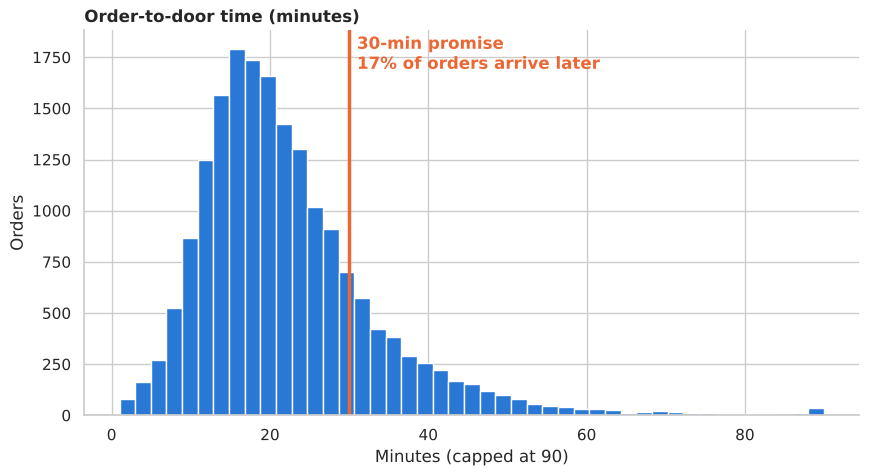

DERIVED RESULT: median wait = 20 min; 17.1% of delivered orders (3,139) broke the 30-minute promise.


In [8]:
fig, ax = plt.subplots()
ax.hist(df['total_minutes'].clip(upper=90), bins=45, color=BLUE, edgecolor='white')
ax.axvline(30, color=ORANGE, lw=2.5)
late = 1 - df['on_time'].mean()
ax.text(31, ax.get_ylim()[1] * 0.9, f"30-min promise\n{late:.0%} of orders arrive later",
        color=ORANGE, fontweight='bold')
ax.set_title('Order-to-door time (minutes)'); ax.set_xlabel('Minutes (capped at 90)'); ax.set_ylabel('Orders')
plt.show()
print(f"DERIVED RESULT: median wait = {df['total_minutes'].median():.0f} min; "
      f"{late:.1%} of delivered orders ({(1-df['on_time']).sum():,}) broke the 30-minute promise.")

### B3.2 Auto-allocation vs manual allocation: the core hypothesis
*Why this chart:* left, a bar of on-time **rate** compares the two methods directly; right, a boxplot shows *where* the difference comes from (allocation delay).

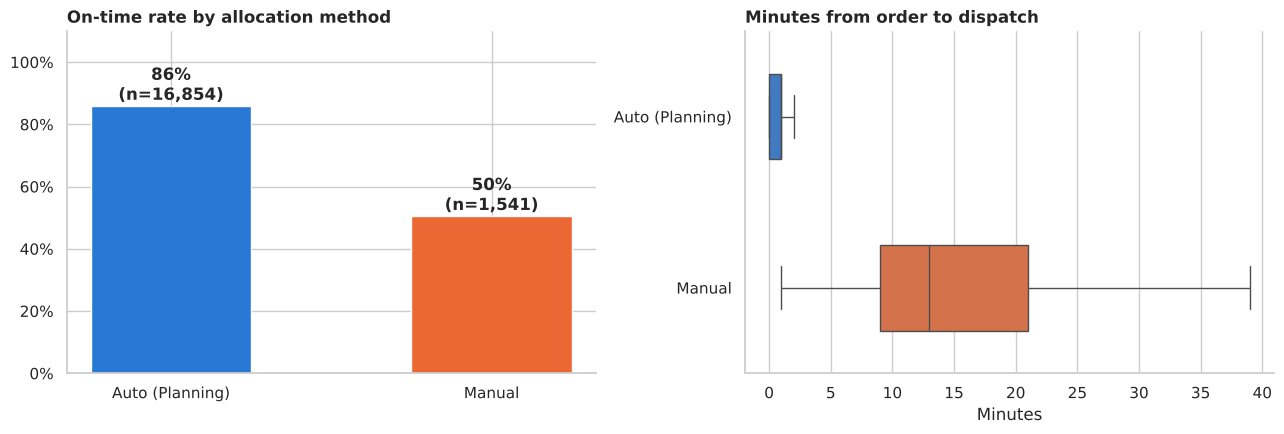

DERIVED RESULT: auto-allocated orders are on time 86% of the time vs 50% for manual. Median dispatch delay: 1 min (auto) vs 13 min (manual).


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rate = df.groupby('allocation')['on_time'].agg(['mean', 'size'])
axes[0].bar(rate.index, rate['mean'], color=[BLUE, ORANGE], width=0.5)
for i, (r, n) in enumerate(zip(rate['mean'], rate['size'])):
    axes[0].text(i, r + 0.02, f"{r:.0%}\n(n={n:,})", ha='center', fontweight='bold')
axes[0].set_ylim(0, 1.1); axes[0].yaxis.set_major_formatter(pct)
axes[0].set_title('On-time rate by allocation method')

sns.boxplot(data=df, y='allocation', x='alloc_delay', ax=axes[1], palette=[BLUE, ORANGE],
            showfliers=False, width=0.5, order=rate.index)
axes[1].set_title('Minutes from order to dispatch'); axes[1].set_ylabel(''); axes[1].set_xlabel('Minutes')
plt.tight_layout(); plt.show()

med = df.groupby('allocation')['alloc_delay'].median()
print(f"DERIVED RESULT: auto-allocated orders are on time {rate.loc['Auto (Planning)','mean']:.0%} of the time "
      f"vs {rate.loc['Manual','mean']:.0%} for manual. Median dispatch delay: "
      f"{med['Auto (Planning)']:.0f} min (auto) vs {med['Manual']:.0f} min (manual).")

### B3.3 Volume and on-time rate through the day
*Why this chart:* two panels sharing the hour axis (instead of one chart with two y-axes, which can mislead). We can see whether busy hours are also the hours where we fail.

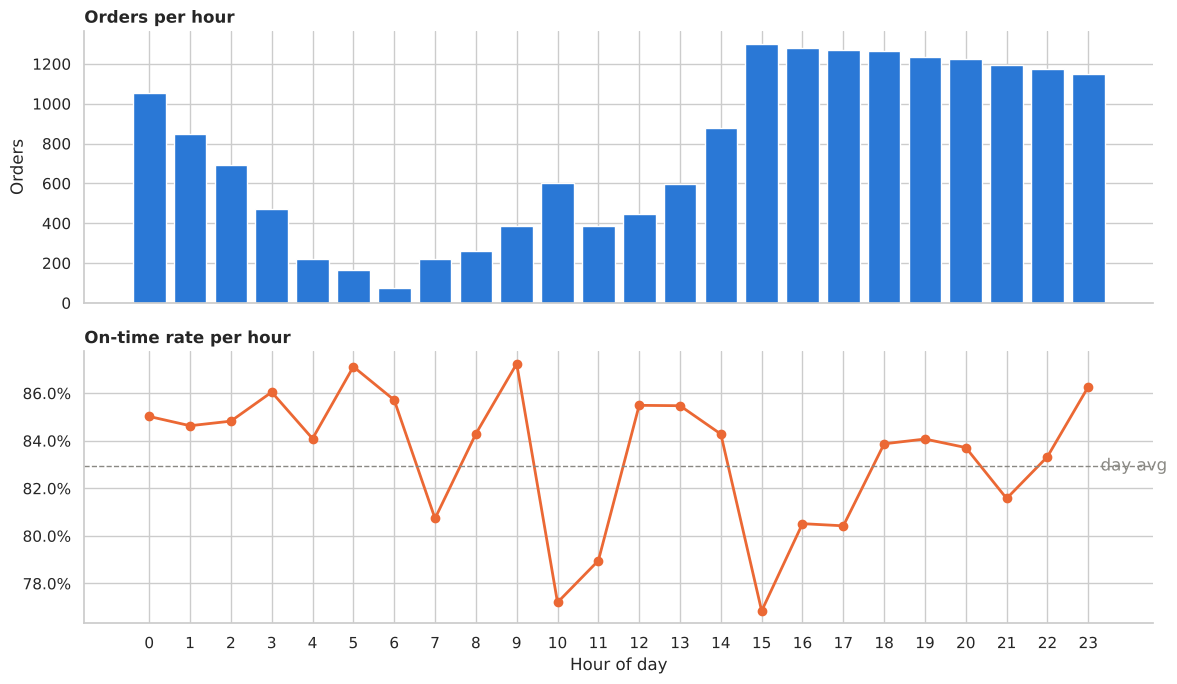

DERIVED RESULT: busiest hour = 15:00 (1,300 orders). Worst on-time hour (min 100 orders) = 15:00 at 77%.


In [10]:
hourly = df.groupby('hour').agg(orders=('on_time', 'size'), on_time=('on_time', 'mean'))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [1, 1]})
a1.bar(hourly.index, hourly['orders'], color=BLUE)
a1.set_title('Orders per hour'); a1.set_ylabel('Orders')
a2.plot(hourly.index, hourly['on_time'], color=ORANGE, marker='o', lw=2)
a2.axhline(df['on_time'].mean(), ls='--', color=GREY, lw=1)
a2.text(23.3, df['on_time'].mean(), 'day avg', va='center', color=GREY)
a2.set_title('On-time rate per hour'); a2.yaxis.set_major_formatter(pct)
a2.set_xlabel('Hour of day'); a2.set_xticks(range(24))
plt.tight_layout(); plt.show()

busy = hourly['orders'].idxmax(); worst = hourly[hourly['orders'] >= 100]['on_time'].idxmin()
print(f"DERIVED RESULT: busiest hour = {busy}:00 ({hourly.loc[busy,'orders']:,} orders). "
      f"Worst on-time hour (min 100 orders) = {worst}:00 at {hourly.loc[worst,'on_time']:.0%}.")

### B3.4 On-time rate by city
*Why this chart:* ranked horizontal bars make it easy to compare a rate across categories; the order count keeps small cities in context.

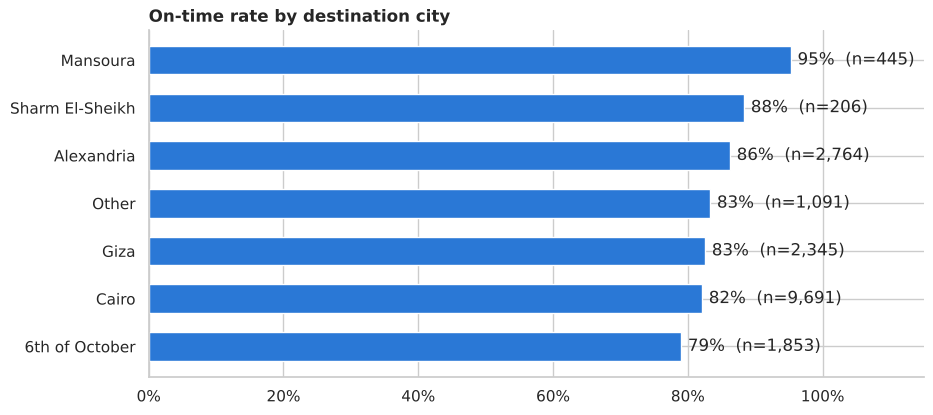

DERIVED RESULT: best = Mansoura (95%), worst = 6th of October (79%).


In [11]:
city = df.groupby('city')['on_time'].agg(['mean', 'size']).sort_values('mean')
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(city.index, city['mean'], color=BLUE, height=0.6)
for y_, (r, n) in enumerate(zip(city['mean'], city['size'])):
    ax.text(r + 0.01, y_, f"{r:.0%}  (n={n:,})", va='center')
ax.set_xlim(0, 1.15); ax.xaxis.set_major_formatter(pct); ax.set_title('On-time rate by destination city')
plt.show()
print(f"DERIVED RESULT: best = {city.index[-1]} ({city['mean'].iloc[-1]:.0%}), "
      f"worst = {city.index[0]} ({city['mean'].iloc[0]:.0%}).")

### B3.5 Slack at dispatch vs probability of being on time
*Why this chart:* we group orders into slack buckets and plot the on-time **rate** per bucket. The S-shape is exactly what logistic regression models, which justifies the choice of model.

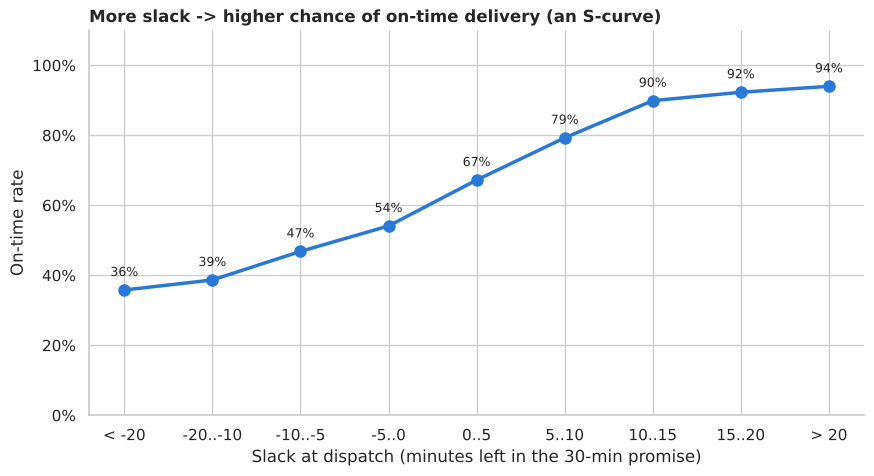

DERIVED RESULT: orders with negative slack are on time only 44% of the time vs 92% with 10+ minutes of slack.


In [12]:
bins = [-np.inf, -20, -10, -5, 0, 5, 10, 15, 20, np.inf]
lab = ['< -20', '-20..-10', '-10..-5', '-5..0', '0..5', '5..10', '10..15', '15..20', '> 20']
sb = df.groupby(pd.cut(df['slack'], bins, labels=lab), observed=True)['on_time'].agg(['mean', 'size'])
fig, ax = plt.subplots()
ax.plot(range(len(sb)), sb['mean'], marker='o', color=BLUE, lw=2.5, ms=8)
for i, (r, n) in enumerate(zip(sb['mean'], sb['size'])):
    ax.text(i, r + 0.04, f"{r:.0%}", ha='center', fontsize=9)
ax.set_xticks(range(len(sb))); ax.set_xticklabels(sb.index)
ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Slack at dispatch (minutes left in the 30-min promise)'); ax.set_ylabel('On-time rate')
ax.set_title('More slack -> higher chance of on-time delivery (an S-curve)')
plt.show()
print(f"DERIVED RESULT: orders with negative slack are on time only {df[df.slack<0].on_time.mean():.0%} of the time "
      f"vs {df[df.slack>=10].on_time.mean():.0%} with 10+ minutes of slack.")

### B3.6 How features relate to each other and to the target
*Why this chart:* a correlation heatmap spots redundant features (multicollinearity hurts coefficient interpretation) and gives a first read of which features move with `on_time`.

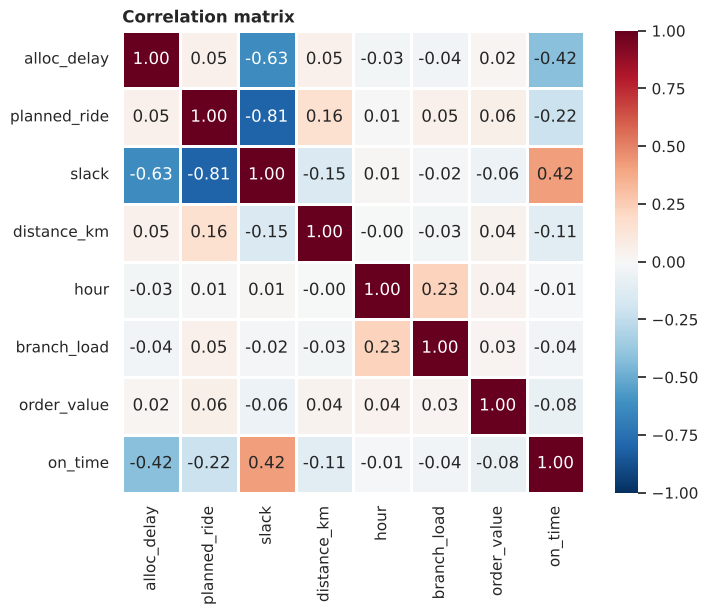

DERIVED RESULT: slack is built from alloc_delay and planned_ride, so they are correlated. That's fine for prediction; for interpretation read slack's coefficient together with them.


In [13]:
num_view = ['alloc_delay', 'planned_ride', 'slack', 'distance_km', 'hour', 'branch_load', 'order_value', 'on_time']
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_view].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=1, square=True)
plt.title('Correlation matrix'); plt.show()
print("DERIVED RESULT: slack is built from alloc_delay and planned_ride, so they are correlated. "
      "That's fine for prediction; for interpretation read slack's coefficient together with them.")

## B4. Build the logistic regression model
Steps:
1. **Split** 75% train / 25% test, *stratified* so both keep the same on-time ratio.
2. **Pre-process inside a Pipeline** so nothing from the test set leaks into training:
   * numbers → `StandardScaler` (puts features on the same scale so coefficients are comparable)
   * categories → `OneHotEncoder`
   * `branch` (100+ values) → `TargetEncoder`: replaces each branch with its historical on-time rate, computed with cross-fitting on the **training data only**
3. **`class_weight='balanced'`**: late orders are the minority (17%); this makes the model pay equal attention to them.

In [14]:
num_features = ['slack', 'alloc_delay', 'planned_ride', 'distance_km', 'hour', 'branch_load', 'order_value']
cat_features = ['allocation', 'Payment Type', 'city']
te_features  = ['branch']

X = df[num_features + cat_features + te_features]
y = df['on_time']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_features),
    ('branch', Pipeline([('te', TargetEncoder(random_state=42)), ('sc', StandardScaler())]), te_features),
])
model = Pipeline([
    ('prep', preprocess),
    ('logreg', LogisticRegression(max_iter=3000, class_weight='balanced')),
])
model.fit(X_train, y_train)
print(f"Trained on {len(X_train):,} orders, testing on {len(X_test):,}.")

Trained on 13,796 orders, testing on 4,599.


## B5. Evaluate: honestly

In [15]:
proba = model.predict_proba(X_test)[:, 1]
pred  = model.predict(X_test)
baseline_acc = y_test.mean()   # always predicting 'on time'

results = pd.Series({
    'Baseline accuracy (always "on time")': baseline_acc,
    'Accuracy':               accuracy_score(y_test, pred),
    'Precision (on time)':    precision_score(y_test, pred),
    'Recall (on time)':       recall_score(y_test, pred),
    'Recall (LATE orders)':   recall_score(y_test, pred, pos_label=0),
    'F1':                     f1_score(y_test, pred),
    'ROC-AUC':                roc_auc_score(y_test, proba),
}).round(3)
display(results.to_frame('Test score'))

cv = cross_val_score(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='roc_auc')
print(f"5-fold cross-validated ROC-AUC: {cv.mean():.3f} ± {cv.std():.3f}  (stable across splits)")
print(classification_report(y_test, pred, target_names=['Late', 'On time']))

# Why is accuracy below the baseline? Compare with an un-weighted model
plain = Pipeline([('prep', preprocess), ('logreg', LogisticRegression(max_iter=3000))]).fit(X_train, y_train)
pp = plain.predict(X_test)
display(pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, pp), accuracy_score(y_test, pred)],
    'Late orders caught (recall)': [recall_score(y_test, pp, pos_label=0), recall_score(y_test, pred, pos_label=0)],
    'ROC-AUC': [roc_auc_score(y_test, plain.predict_proba(X_test)[:, 1]), roc_auc_score(y_test, proba)],
}, index=['Un-weighted model', "class_weight='balanced' (ours)"]).round(3))

,Test score
"Baseline accuracy (always ""on time"")",0.829
Accuracy,0.796
Precision (on time),0.932
Recall (on time),0.813
Recall (LATE orders),0.712
F1,0.868
ROC-AUC,0.859


5-fold cross-validated ROC-AUC: 0.855 ± 0.011  (stable across splits)
              precision    recall  f1-score   support

        Late       0.44      0.71      0.54       785
     On time       0.93      0.81      0.87      3814

    accuracy                           0.80      4599
   macro avg       0.69      0.76      0.71      4599
weighted avg       0.85      0.80      0.81      4599



,Accuracy,Late orders caught (recall),ROC-AUC
Un-weighted model,0.868,0.381,0.859
class_weight='balanced' (ours),0.796,0.712,0.859


**Why is our accuracy (≈0.80) *below* the 0.83 baseline, and why is that fine?**
The baseline never predicts "late", so it catches **0%** of late orders. The un-weighted model maximises accuracy by mostly saying "on time" and misses most late orders. Our balanced model gives up a little accuracy to **catch about 7 in 10 late orders**, which is the whole point of the tool. ROC-AUC is the same for both, because the ranking is the same and only the decision threshold moves. **Pick the metric that matches the business goal, not the one that looks biggest.**

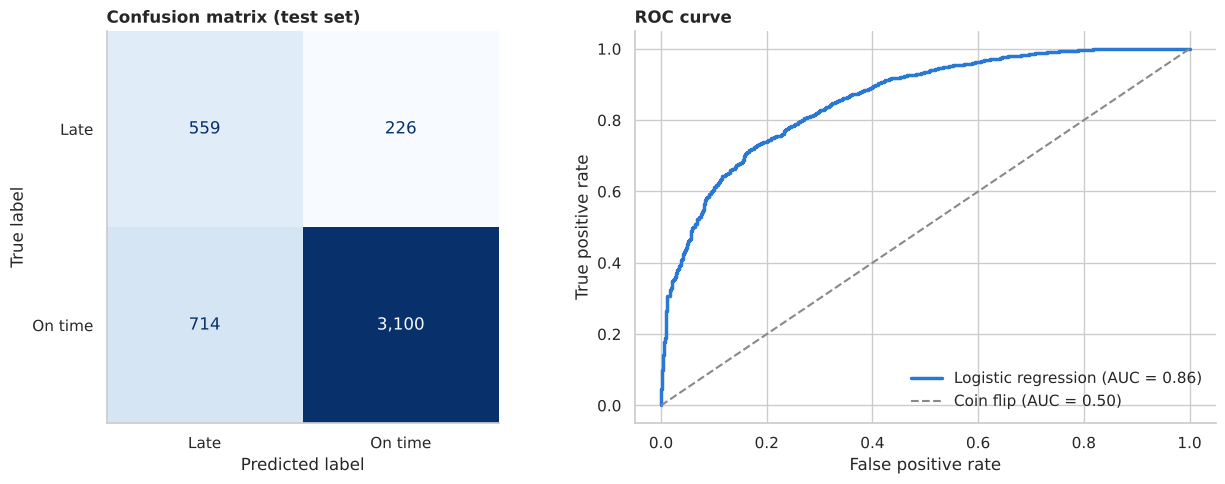

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Late', 'On time']).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format=',')
axes[0].set_title('Confusion matrix (test set)'); axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, color=BLUE, lw=2.5, label=f"Logistic regression (AUC = {roc_auc_score(y_test, proba):.2f})")
axes[1].plot([0, 1], [0, 1], ls='--', color=GREY, label='Coin flip (AUC = 0.50)')
axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate')
axes[1].set_title('ROC curve'); axes[1].legend(loc='lower right', frameon=False)
plt.tight_layout(); plt.show()

## B6. Interpret: what drives on-time delivery?
Coefficients are on standardised features, so their sizes are comparable. We convert them to **odds ratios** ($e^\beta$):
* **> 1** → raises the odds of being on time
* **< 1** → lowers them

For a numeric feature, the odds ratio is per **1 standard deviation** increase.

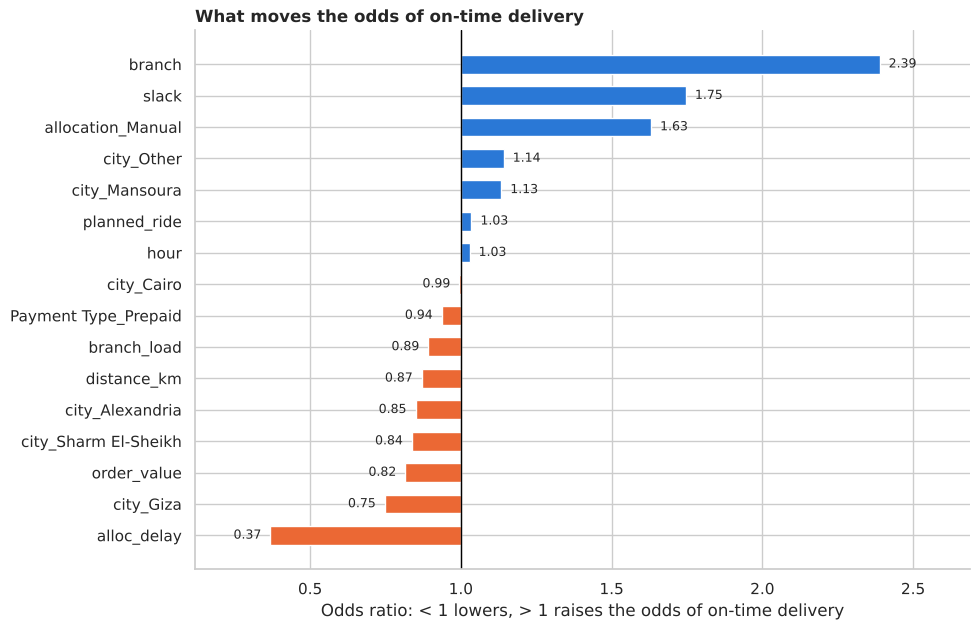

DERIVED RESULT (top 5 drivers by strength of effect):
  alloc_delay                    odds ratio 0.37
  branch                         odds ratio 2.39
  slack                          odds ratio 1.75
  allocation_Manual              odds ratio 1.63
  city_Giza                      odds ratio 0.75


In [17]:
names = model.named_steps['prep'].get_feature_names_out()
names = [n.split('__')[1] for n in names]
coef = pd.Series(model.named_steps['logreg'].coef_[0], index=names)
odds = np.exp(coef).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
colors = [ORANGE if v < 1 else BLUE for v in odds]
ax.barh(odds.index, odds.values - 1, left=1, color=colors, height=0.6)
ax.axvline(1, color='black', lw=1)
for y_, v in enumerate(odds.values):
    ax.text(v + (0.03 if v >= 1 else -0.03), y_, f"{v:.2f}", va='center', ha='left' if v >= 1 else 'right', fontsize=9)
ax.set_xlim(odds.min() - 0.25, odds.max() + 0.3)
ax.set_xlabel('Odds ratio: < 1 lowers, > 1 raises the odds of on-time delivery')
ax.set_title('What moves the odds of on-time delivery')
plt.show()

print("DERIVED RESULT (top 5 drivers by strength of effect):")
for f in np.log(odds).abs().sort_values(ascending=False).index[:5]:
    print(f"  {f:30s} odds ratio {odds[f]:.2f}")

**How to read it (talking points):**
* **`alloc_delay` is the biggest negative driver.** Each standard deviation of extra dispatch delay cuts the odds of on-time delivery by roughly two-thirds.
* **`branch` and `slack` are the biggest positive drivers.** Orders from historically good branches, and orders with spare minutes, are far more likely to arrive on time.
* **Why does `allocation_Manual` show > 1 when manual orders are late far more often (B3.2)?** A coefficient shows the effect *holding the other features constant*. Manual allocation hurts **through** the longer dispatch delay, which `alloc_delay` already captures. Once delay is accounted for, "manual" adds nothing bad on its own. This is a classic lesson: **a coefficient is a conditional effect, not a raw comparison.**

## B7. Choosing the decision threshold (a business decision)
The default threshold is 0.5. Lowering or raising it trades **catching more late orders** against **raising more false alarms** for the supervisor.

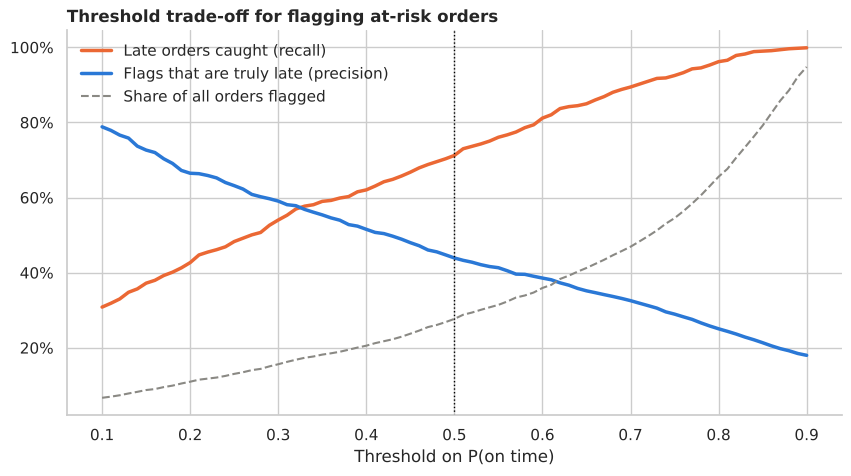

DERIVED RESULT: at threshold 0.5 the model flags 28% of orders and catches 71% of the late ones; 44% of flags are truly late.


In [18]:
th = np.linspace(0.1, 0.9, 81)
late_recall, late_precision, flagged = [], [], []
for t in th:
    p_late = (proba < t)               # flag as 'at risk of being late'
    tp = (p_late & (y_test == 0)).sum()
    late_recall.append(tp / (y_test == 0).sum())
    late_precision.append(tp / max(p_late.sum(), 1))
    flagged.append(p_late.mean())

fig, ax = plt.subplots()
ax.plot(th, late_recall, lw=2.5, color=ORANGE, label='Late orders caught (recall)')
ax.plot(th, late_precision, lw=2.5, color=BLUE, label='Flags that are truly late (precision)')
ax.plot(th, flagged, lw=1.5, ls='--', color=GREY, label='Share of all orders flagged')
ax.axvline(0.5, color='black', lw=1, ls=':')
ax.yaxis.set_major_formatter(pct); ax.set_xlabel('Threshold on P(on time)')
ax.set_title('Threshold trade-off for flagging at-risk orders'); ax.legend(frameon=False)
plt.show()
i = np.argmin(abs(th - 0.5))
print(f"DERIVED RESULT: at threshold 0.5 the model flags {flagged[i]:.0%} of orders and catches "
      f"{late_recall[i]:.0%} of the late ones; {late_precision[i]:.0%} of flags are truly late.")

## B8. "Can we get the score close to 1?": the leakage lesson
We *can* get near-perfect numbers, but only by cheating. Below we add `actual_ride` (the real ride time). The target is literally built from it, and it is **only known after the delivery is finished**, so the model would be useless at dispatch time.

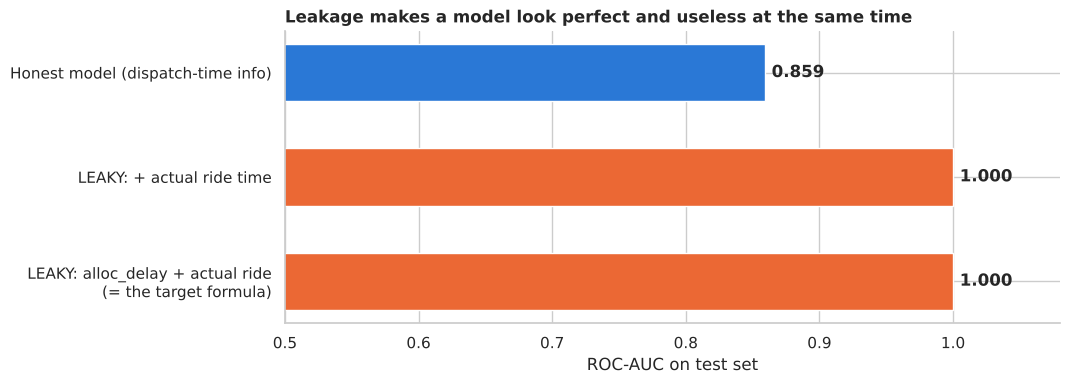

In [19]:
def auc_with(features):
    Xl = df[features]; Xtr, Xte, ytr, yte = train_test_split(Xl, y, test_size=0.25, random_state=42, stratify=y)
    p = Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=3000))]).fit(Xtr, ytr)
    return roc_auc_score(yte, p.predict_proba(Xte)[:, 1])

compare = pd.Series({
    'Honest model (dispatch-time info)': roc_auc_score(y_test, proba),
    'LEAKY: + actual ride time': auc_with(num_features + ['actual_ride']),
    'LEAKY: alloc_delay + actual ride\n(= the target formula)': auc_with(['alloc_delay', 'actual_ride']),
})
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(compare.index[::-1], compare.values[::-1], color=[ORANGE, ORANGE, BLUE], height=0.55)
for y_, v in enumerate(compare.values[::-1]):
    ax.text(v + 0.005, y_, f"{v:.3f}", va='center', fontweight='bold')
ax.set_xlim(0.5, 1.08); ax.set_xlabel('ROC-AUC on test set')
ax.set_title('Leakage makes a model look perfect and useless at the same time')
plt.show()

**Takeaway for class:** a model is only as good as the information available **at the time you'd use it**. Our honest model scores an **AUC ≈ 0.86**, well above a coin flip (0.50). For an operations problem with traffic, weather and customers who don't answer the door, that is a strong, usable result. A score near 1.0 here would be a red flag for leakage, not a success.

**How to legitimately push it higher** (needs data this file doesn't have): rider experience and current workload, live traffic, weather, kitchen prep time, customer's past delivery history, several weeks of data (this file covers one day).

## B9. Using the model: score orders at dispatch

In [20]:
scored = X_test.copy()
scored['P(on time)'] = proba
scored['Risk'] = pd.cut(scored['P(on time)'], [0, 0.4, 0.6, 1], labels=['High', 'Medium', 'Low'])
scored['Actually on time'] = y_test.values

risk = scored.groupby('Risk', observed=True).agg(orders=('Risk', 'size'),
                                                 actual_on_time=('Actually on time', 'mean'))
display(risk.style.format({'actual_on_time': '{:.0%}'}))
print("DERIVED RESULT: the risk bands separate cleanly. 'High risk' orders really are late far more often.")
display(scored.sort_values('P(on time)').head(10)[['allocation', 'alloc_delay', 'planned_ride', 'slack',
                                                   'city', 'P(on time)', 'Actually on time']]
        .style.format({'P(on time)': '{:.1%}', 'slack': '{:.0f}'}))

,orders,actual_on_time
Risk,,
High,945,48%
Medium,707,79%
Low,2947,95%


DERIVED RESULT: the risk bands separate cleanly. 'High risk' orders really are late far more often.


,allocation,alloc_delay,planned_ride,slack,city,P(on time),Actually on time
13429,Auto (Planning),91.000000,14.000000,-75,Other,0.0%,0
6626,Manual,87.000000,12.000000,-69,Other,0.0%,0
10624,Manual,78.000000,17.000000,-65,Cairo,0.0%,0
15853,Manual,95.000000,10.000000,-75,Cairo,0.0%,0
11015,Manual,89.000000,8.000000,-67,6th of October,0.0%,0
5229,Manual,68.000000,43.000000,-81,Cairo,0.0%,0
14518,Manual,83.000000,14.000000,-67,Cairo,0.0%,0
16429,Auto (Planning),87.000000,11.000000,-68,Cairo,0.0%,0
10382,Manual,69.000000,38.000000,-77,Cairo,0.0%,0
15156,Manual,72.000000,21.000000,-63,Cairo,0.0%,0


## B10. Findings & recommendations

| # | Finding | Recommendation |
|---|---|---|
| 1 | ~1 in 6 delivered orders breaks the 30-min promise | Track on-time % as the headline KPI |
| 2 | Auto-allocated orders are on time far more often than manual ones, mainly because dispatch is much faster | Expand auto-allocation; manual only for exceptions |
| 3 | **Slack at dispatch** is the strongest driver: once allocation + ETA eat the 30 minutes, the order is likely late | Alert supervisors when slack < 5 min |
| 4 | Branch track record matters a lot | Review the worst branches' kitchen and rider capacity |
| 5 | Logistic regression flags at-risk orders with AUC ≈ 0.86 at dispatch time | Use the risk score to prioritise riders and pre-warn customers |

*Limitation: one day of data (20 Sep 2022). Results should be validated on several weeks before rollout.*